# Descriptive Statistics

In this notebook we'll implement, review, and interpret various descriptive statistics including the mean, median, mode, variance, standard deviation, range, covariance and correlation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Importing the data

In [2]:
# import data as df

df = pd.read_csv('./data/top10s_cleaned.csv')

In [3]:
df.head()

,title,artist,top genre,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
0,"Hey, Soul Sister",Train,neo mellow,2010,97,89,67,-4,8,80,217,19,4,83
1,Love The Way You Lie,Eminem,hip hop,2010,87,93,75,-5,52,64,263,24,23,82
2,TiK ToK,Kesha,dance pop,2010,120,84,76,-3,29,71,200,10,14,80
3,Bad Romance,Lady Gaga,dance pop,2010,119,92,70,-4,8,71,295,0,4,79
4,Just the Way You Are,Bruno Mars,pop,2010,109,84,64,-5,9,43,221,2,4,78


## Q: How many observations are there? How many variables?

In [4]:
df.shape

(586, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 586 entries, 0 to 585
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   title      586 non-null    object
 1   artist     586 non-null    object
 2   top genre  586 non-null    object
 3   year       586 non-null    int64 
 4   bpm        586 non-null    int64 
 5   nrgy       586 non-null    int64 
 6   dnce       586 non-null    int64 
 7   dB         586 non-null    int64 
 8   live       586 non-null    int64 
 9   val        586 non-null    int64 
 10  dur        586 non-null    int64 
 11  acous      586 non-null    int64 
 12  spch       586 non-null    int64 
 13  pop        586 non-null    int64 
dtypes: int64(11), object(3)
memory usage: 64.2+ KB


## Q: Which variables are categorical, and which variables are quantitative? 

In [6]:
df.head()

,title,artist,top genre,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
0,"Hey, Soul Sister",Train,neo mellow,2010,97,89,67,-4,8,80,217,19,4,83
1,Love The Way You Lie,Eminem,hip hop,2010,87,93,75,-5,52,64,263,24,23,82
2,TiK ToK,Kesha,dance pop,2010,120,84,76,-3,29,71,200,10,14,80
3,Bad Romance,Lady Gaga,dance pop,2010,119,92,70,-4,8,71,295,0,4,79
4,Just the Way You Are,Bruno Mars,pop,2010,109,84,64,-5,9,43,221,2,4,78


In [7]:
df['year'].value_counts()

2015    94
2016    73
2013    70
2017    64
2018    62
2014    57
2010    51
2011    49
2012    35
2019    31
Name: year, dtype: int64

## Summarizing categorical variables

What genres are most common? What genres are least common?

There's lots more we can do with categorical variables, but for today let's look at raw counts.

In [8]:
df['top genre'].value_counts()

dance pop           324
pop                 120
house                30
electropop           21
hip hop              16
boy band             15
r&b                  14
indie pop            14
neo mellow            9
british soul          9
alternative rock      7
latin                 4
electro               3
Name: top genre, dtype: int64

In [9]:
324/len(df)

0.552901023890785

In [10]:
df['top genre'].value_counts(normalize = True)

dance pop           0.552901
pop                 0.204778
house               0.051195
electropop          0.035836
hip hop             0.027304
boy band            0.025597
r&b                 0.023891
indie pop           0.023891
neo mellow          0.015358
british soul        0.015358
alternative rock    0.011945
latin               0.006826
electro             0.005119
Name: top genre, dtype: float64

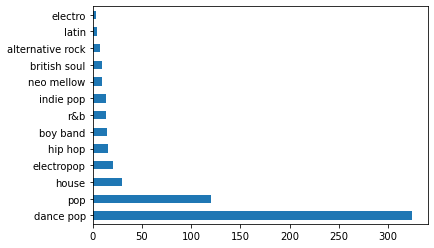

In [11]:
df['top genre'].value_counts().plot(kind = 'barh');

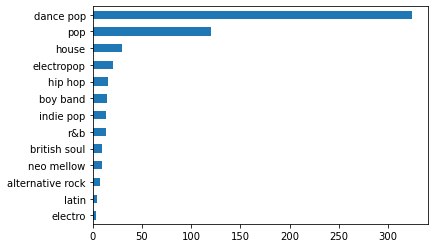

In [12]:
df['top genre'].value_counts().sort_values(ascending = True).plot(kind = 'barh');

----

## Summarizing quantitative variables

Some people find that calculating summary statistics 'by hand' (using for-loops) helps them understand the formulas better. We'll calculate these 'by hand' first, then we'll use pandas.

You'll use numpy and/or pandas to calculate these in the future. Numpy and pandas are more precise in handling floating point operations. They also tend to be faster.

### Calculating the mean/average

We calculate the mean by summing all the values, then dividing the sum by the number of values.

In sigma notation, that looks like this:

$$\bar{x} =\frac 1n\sum_{i=1}^nx_i$$

Let's hand-code the **mean bpm**, then compare it to pandas:

In [14]:
bpm_sum = 0

for value in df['bpm']:
    bpm_sum += value
    
print(bpm_sum)

bpm_sum / len(df['bpm'])

69653


118.8617747440273

In [15]:
sum(df['bpm']) / len(df['bpm'])

118.8617747440273

In [16]:
np.mean(df['bpm'])

118.8617747440273

In [17]:
df['bpm'].mean()

118.8617747440273

### Calculating the median

We calculate the median by sorting all the data points from smallest to largest, then identifying the number in the middle of the ordered list.

If there is an odd number of values, the middle value is the median. If there is an even number of values, the average of the middle two values is the median.

The median is considered robust to outliers. If there are one or two extreme values, the median won't be as effected by them as much as the mean will be.

We'll use `len()` and `sorted()` to calculate the median by hand, then we'll use `np.median()`.

In [18]:
sorted(df['bpm'])

[43,
 63,
 65,
 73,
 75,
 75,
 76,
 77,
 77,
 77,
 77,
 78,
 79,
 79,
 79,
 80,
 80,
 80,
 80,
 80,
 81,
 82,
 82,
 82,
 82,
 82,
 82,
 83,
 83,
 83,
 84,
 84,
 84,
 85,
 85,
 86,
 86,
 86,
 86,
 86,
 86,
 87,
 87,
 87,
 87,
 87,
 88,
 89,
 90,
 90,
 90,
 90,
 90,
 90,
 90,
 91,
 91,
 91,
 91,
 92,
 92,
 92,
 92,
 92,
 92,
 92,
 92,
 92,
 93,
 93,
 93,
 93,
 93,
 93,
 93,
 93,
 93,
 93,
 94,
 94,
 94,
 94,
 94,
 94,
 94,
 94,
 95,
 95,
 95,
 95,
 95,
 95,
 95,
 95,
 95,
 95,
 95,
 95,
 95,
 96,
 96,
 96,
 96,
 96,
 96,
 97,
 97,
 97,
 97,
 97,
 97,
 98,
 98,
 98,
 98,
 98,
 98,
 99,
 99,
 99,
 99,
 99,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 100,
 101,
 102,
 102,
 102,
 102,
 102,
 102,
 102,
 102,
 102,
 102,
 103,
 103,
 103,
 103,
 103,
 103,
 103,
 104,
 104,
 104,
 104,
 104,
 104,
 104,
 104,
 104,
 104,
 105,
 105,
 105,
 105,
 105,


In [19]:
sorted_bpm = sorted(df['bpm'])

In [21]:
len(sorted_bpm) / 2

293.0

In [22]:
sorted_bpm[293]

120

In [27]:
sorted_bpm[292]

120

In [25]:
np.median(df['bpm'])

120.0

In [26]:
df['bpm'].median()

120.0

In [28]:
x = list(range(1, 7))

x

[1, 2, 3, 4, 5, 6]

In [29]:
len(x) / 2

3.0

In [31]:
x[3]

4

In [32]:
x[3-1]

3

In [33]:
(x[3] + x[3-1]) / 2

3.5

In [34]:
np.median(x)

3.5

In [35]:
type(df['bpm'])

pandas.core.series.Series

In [36]:
type(df['bpm'].values)

numpy.ndarray

### Calculating the mode

The mode is the value that shows up most frequently. Sometimes there's more than one mode, and sometimes there _isn't_ a mode. This is more rarely reported than the mean and median.

To calculate the mode, we'll use the scipy's `stats` module.

In [38]:
df['bpm'].mode()[0]

120

In [41]:
stats.mode(df['bpm'])[0][0]

120

In [44]:
df['bpm'].value_counts().head(1)

120    44
Name: bpm, dtype: int64

### Calculating range

Recall that the range is given by the biggest number in the list of values, minus the smallest values.

The max and min values often of interest themselves, too!

In [47]:
sorted_bpm[-1] - sorted_bpm[0]

163

In [48]:
max(df['bpm']) - min(df['bpm'])

163

In [49]:
df['bpm'].max() - df['bpm'].min()

163

## Variance and standard deviation

Variance and standard deviation tell us about how much the data vary.

Variance is given by:

$$variance = \frac {\sum{(x_i - \bar{x})^2}} {n}$$

And standard deviation is given by:

$$s = \sqrt{\frac {\sum{(x_i - \bar{x})^2}} {n}}$$

Let's calculate variance and standard deviation by hand, then use numpy:

In [50]:
df['bpm'].var()

594.9911175286599

In [51]:
mean_bpm = df['bpm'].mean()

In [52]:
sum(((df['bpm'] - mean_bpm) ** 2))

348069.803754266

In [55]:
bpm_var = ((df['bpm'] - mean_bpm) ** 2).sum() / (len(df) - 1)

bpm_var

594.9911175286602

In [56]:
np.sqrt(bpm_var)

24.39243976171019

In [57]:
df['bpm'].std()

24.392439761710182

## Visualizing a quantitative variable

The summary statistics we've looked at have been useful, but oftentimes, looking at the data itself is even more valuable. Let's take a look at a **histogram** of bpm:

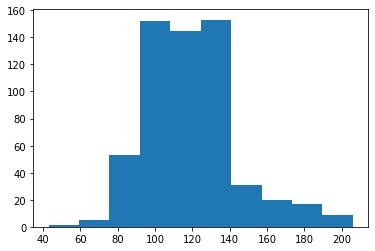

In [58]:
plt.hist(df['bpm']);

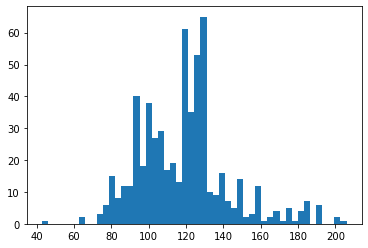

In [59]:
plt.hist(df['bpm'], bins = 50);

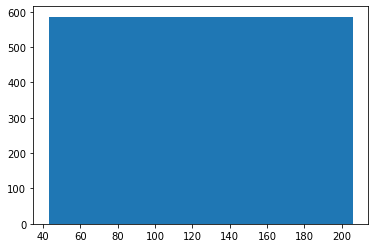

In [60]:
# please, please don't do this
plt.hist(df['bpm'], bins = 1);

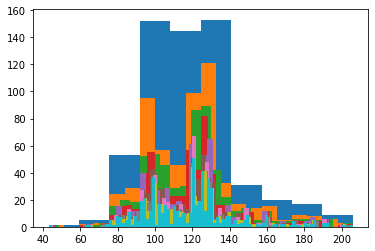

In [61]:
for i in range(10, 101, 10):
    plt.hist(df['bpm'], bins = i);

<AxesSubplot:>

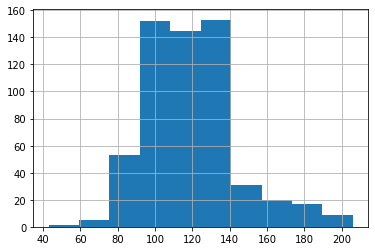

In [62]:
df['bpm'].hist()

## In practice... think about using `describe()`:

Pandas lets us look at descriptive statistics for all of the numeric columns very quickly and conveniently by running `df.describe()`.

**Note**: Don't screenshot this and embed it into a slide deck. Don't! This is **too much information** for a non-technical presentation. Find a prettier, more focused way to present descriptive statistics that you want to convey to an audience.

In [63]:
df.describe()

,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
count,586.000000,586.000000,586.000000,586.000000,586.000000,586.000000,586.000000,586.000000,586.000000,586.000000,586.000000
mean,2014.587031,118.861775,70.614334,64.590444,-5.476109,17.883959,52.315700,224.593857,14.257679,8.290102,66.539249
std,2.612940,24.392440,16.022252,13.128016,1.709784,13.146259,22.428103,34.180150,20.569669,7.301877,14.376001
min,2010.000000,43.000000,4.000000,23.000000,-15.000000,2.000000,4.000000,134.000000,0.000000,3.000000,0.000000
25%,2013.000000,100.000000,61.000000,57.000000,-6.000000,9.000000,35.000000,202.000000,2.000000,4.000000,60.000000
50%,2015.000000,120.000000,74.000000,66.000000,-5.000000,12.000000,52.000000,220.500000,6.000000,5.000000,69.000000
75%,2017.000000,129.000000,82.000000,73.000000,-4.000000,24.000000,69.000000,239.750000,17.000000,9.000000,76.000000
max,2019.000000,206.000000,98.000000,97.000000,-2.000000,74.000000,98.000000,424.000000,99.000000,48.000000,99.000000


## Covariance and correlation

Covariances are difficult to compare to each other because they're not **standardized**. We can't compare the covariances of (`bpm`, `nrgy`) and (`bpm`, `dnce`).

Instead we can use the correlation, which measures the same effect but reports it as a range from -1 to 1. 1 represents perfect covariance and correlation, 0 represents no correlation, and -1 one represents perfect inverse correlation.

$$corr(X,Y) = \frac {cov(X,Y)} {\sigma_X\sigma_Y} = \frac {\mathbb{E}[(\mathbf{X}-\mathbb{E}[\mathbf{X}])(\mathbf{Y}-\mathbb{E}[\mathbf{Y}])]} {\sigma_X\sigma_Y}$$

Note that the variance is always positive, making the denominator positive. So, the sign of the covariance between $X$ and $Y$ is the same as the sign of their correlation.

Correlation measures how variables related to each other.

It's important to look at variables visually in addition to calculating summary statistics. The best way to understand how two continous quantitative variables are related is by looking at a scatter plot.

Run the following code to scatter the bpm and energy variables:

Text(0, 0.5, 'nrgy')

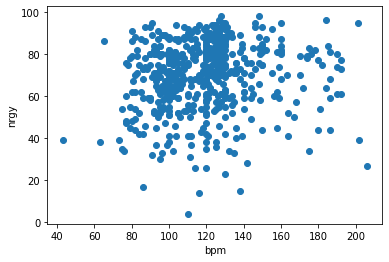

In [64]:
plt.scatter(data = df,
           x = 'bpm', 
           y = 'nrgy')
plt.xlabel('bpm')
plt.ylabel('nrgy')

## Calculating correlation:


In [65]:
corr_df = df[['bpm', 'nrgy']].corr()

corr_df

,bpm,nrgy
bpm,1.000000,0.101311
nrgy,0.101311,1.000000


<AxesSubplot:>

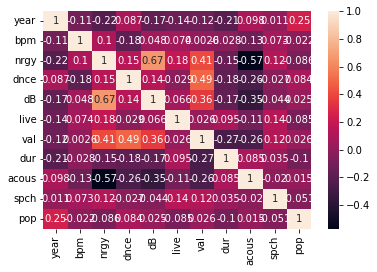

In [66]:
import seaborn as sns

sns.heatmap(df.corr(), annot = True)

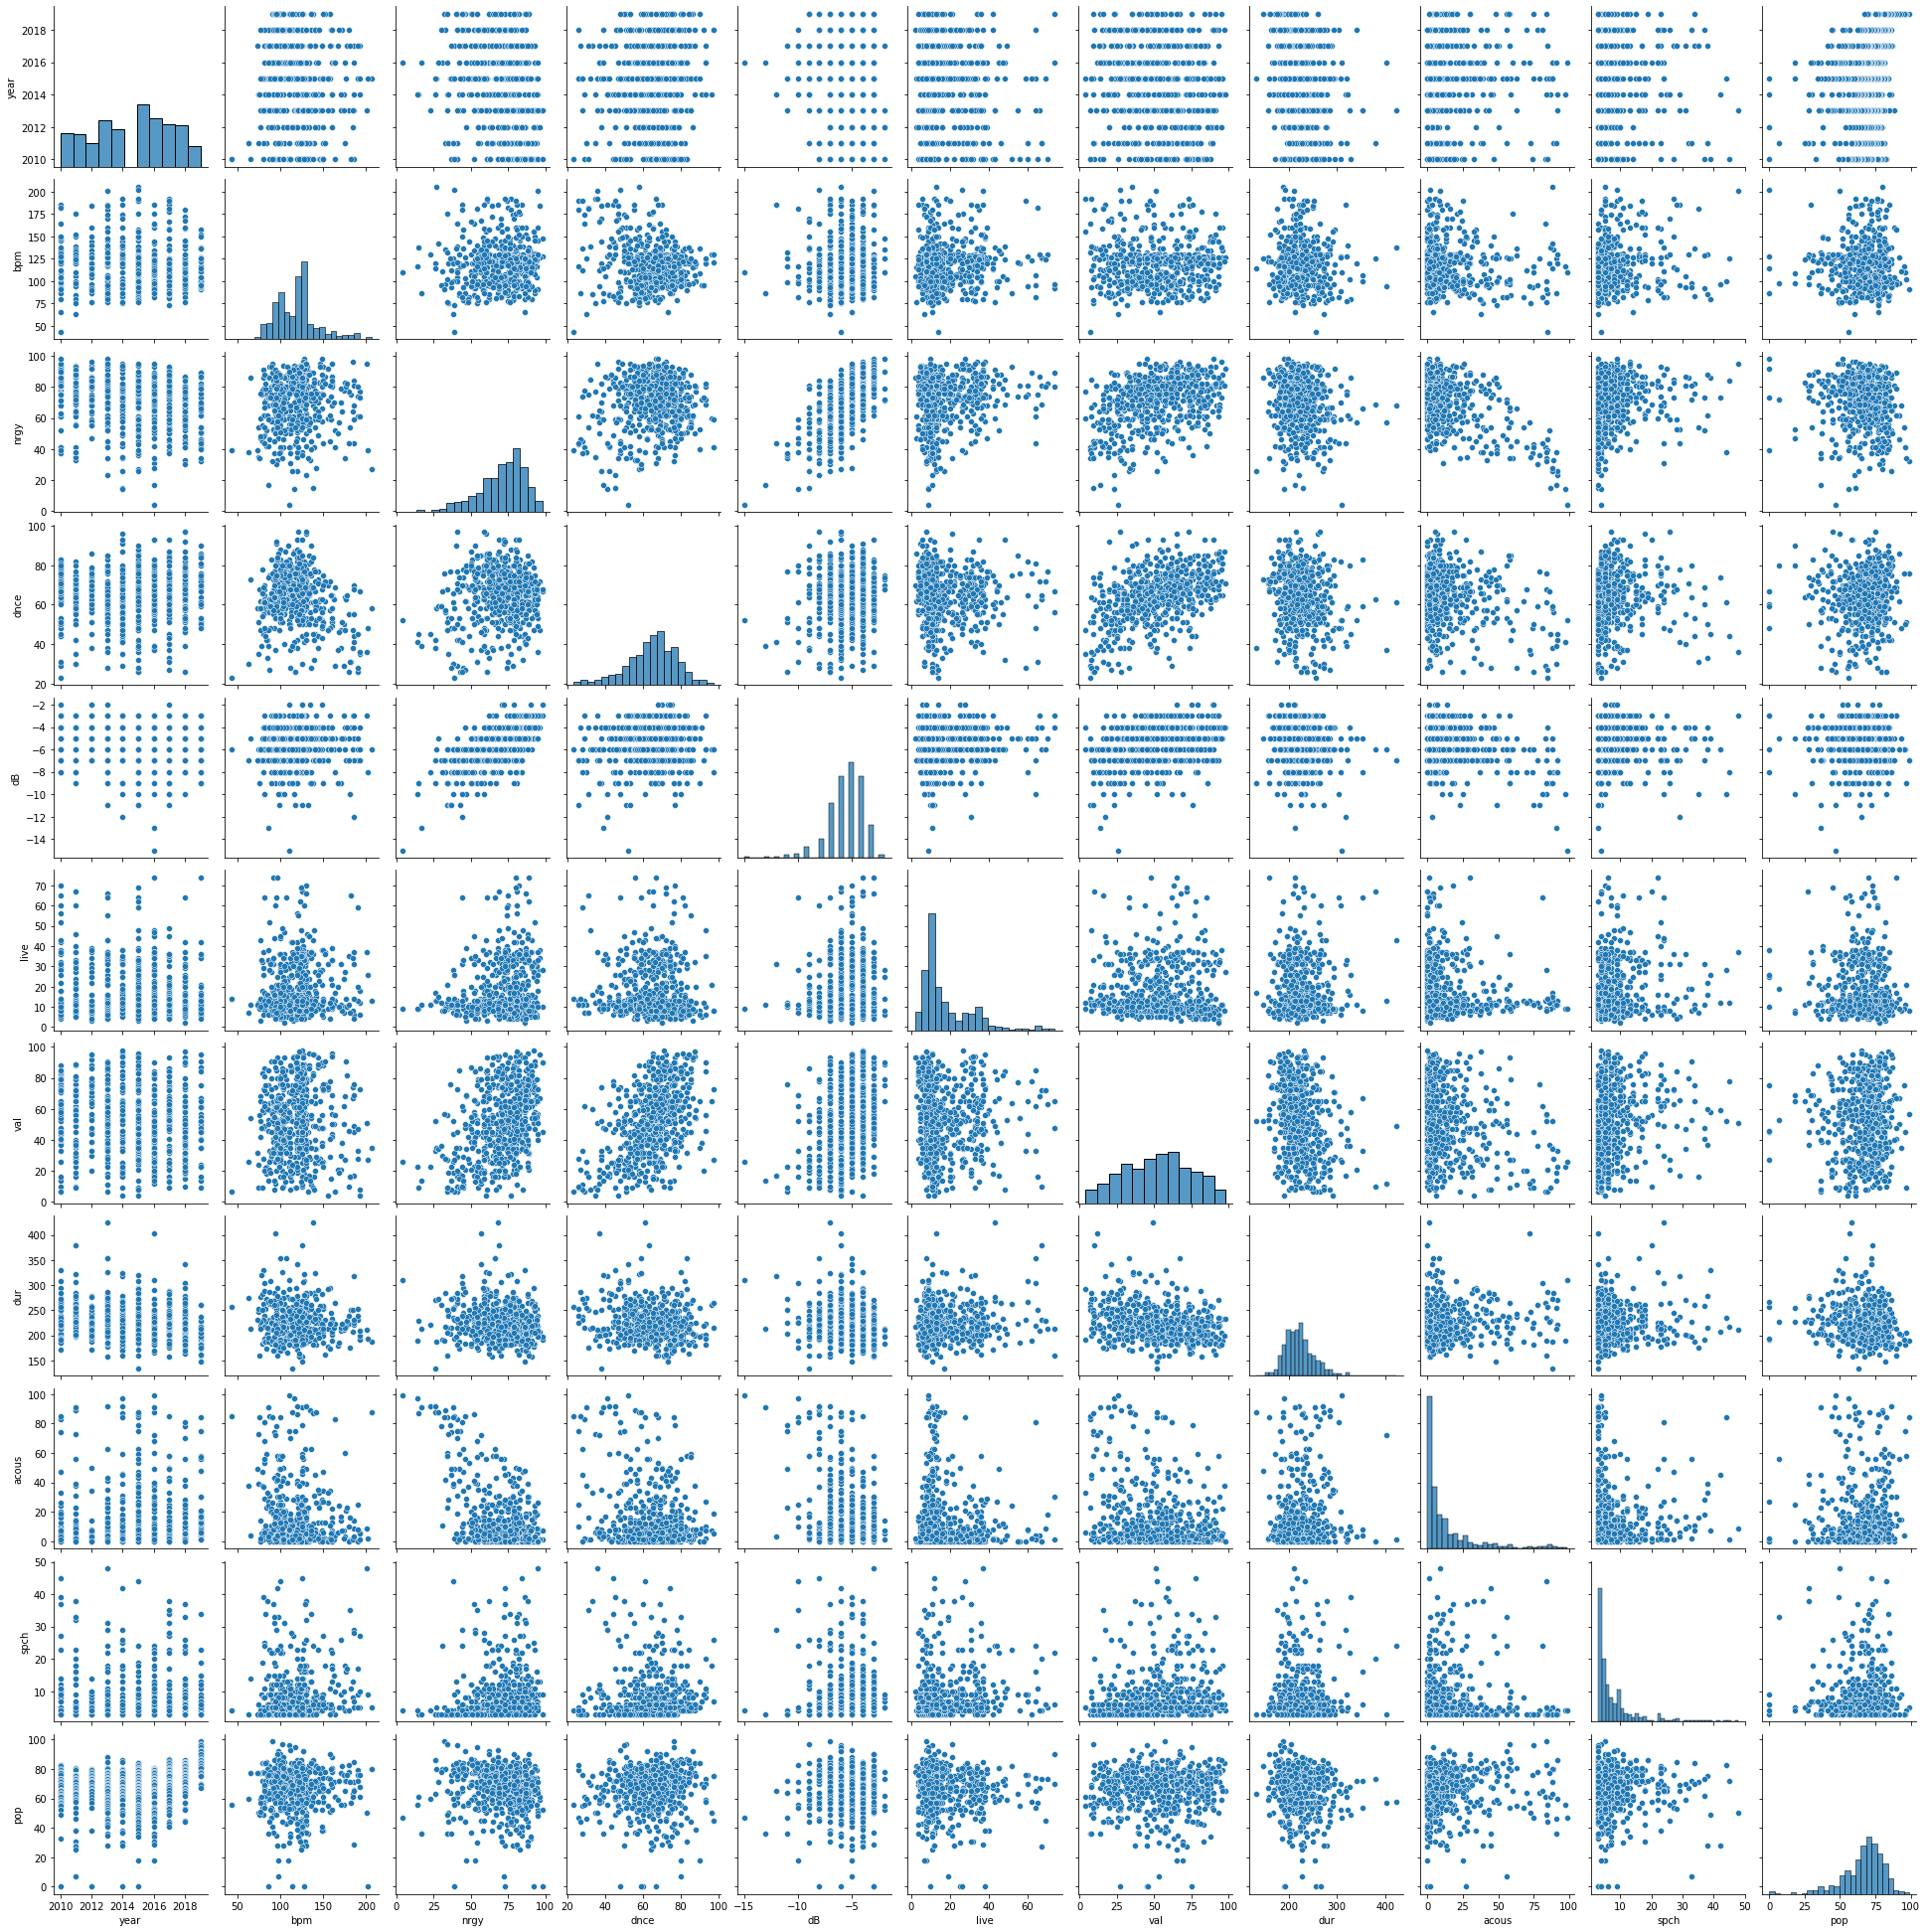

In [67]:
sns.pairplot(df);